<a href="https://colab.research.google.com/github/deva123932/CSA-4703-DL/blob/main/exp_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Task 1: Building Matrices in NumPy
We will initialize the Customer-Genre matrix ($6 \times 5$) and the Genre-Book matrix ($5 \times 4$) with random ratings and weights.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Set random seed for reproducibility
np.random.seed(42)

# 6 customers, 5 genres (ratings 1 to 5)
customer_genre = np.random.randint(1, 6, size=(6, 5)).astype(float)

# 5 genres, 4 books (weights between 0 and 1)
genre_book = np.random.rand(5, 4)

print("Customer-Genre Matrix (6x5):\n", customer_genre)
print("\nGenre-Book Matrix (5x4):\n", np.round(genre_book, 2))

Customer-Genre Matrix (6x5):
 [[4. 5. 3. 5. 5.]
 [2. 3. 3. 3. 5.]
 [4. 3. 5. 2. 4.]
 [2. 4. 5. 1. 4.]
 [2. 5. 4. 1. 1.]
 [3. 3. 2. 4. 4.]]

Genre-Book Matrix (5x4):
 [[0.37 0.46 0.79 0.2 ]
 [0.51 0.59 0.05 0.61]
 [0.17 0.07 0.95 0.97]
 [0.81 0.3  0.1  0.68]
 [0.44 0.12 0.5  0.03]]


## Task 2: Compute Fundamental Matrix Operations
We compute the dot product (matrix multiplication), matrix transpose, the element-wise operations, and the pseudo-inverse (since standard inverse is only defined for square matrices).

In [3]:
# 1. Matrix Product (Score Matrix)
score_matrix = np.dot(customer_genre, genre_book)

# 2. Transpose
customer_genre_T = customer_genre.T

# 3. Pseudo-inverse (since matrices are non-square)
pseudo_inverse_cg = np.linalg.pinv(customer_genre)

# 4. Element-wise operation (scaling values)
elementwise_scaled = customer_genre * 1.5

print("Matrix Product (Score Matrix 6x4):\n", np.round(score_matrix, 2))
print("\nTranspose of Customer-Genre (5x6):\n", customer_genre_T)
print("\nPseudo-inverse (5x6):\n", np.round(pseudo_inverse_cg, 2))
print("\nElement-wise Scaled Ratings (x 1.5):\n", elementwise_scaled)

Matrix Product (Score Matrix 6x4):
 [[10.79  7.11  9.18 10.33]
 [ 7.41  4.41  7.33  7.34]
 [ 7.24  5.02 10.2   8.96]
 [ 6.21  4.4   8.58  8.48]
 [ 5.23  4.56  6.19  8.02]
 [ 7.98  4.98  6.76  7.23]]

Transpose of Customer-Genre (5x6):
 [[4. 2. 4. 2. 2. 3.]
 [5. 3. 3. 4. 5. 3.]
 [3. 3. 5. 5. 4. 2.]
 [5. 3. 2. 1. 1. 4.]
 [5. 5. 4. 4. 1. 4.]]

Pseudo-inverse (5x6):
 [[ 1.33 -1.17  0.2   0.65 -0.75 -0.85]
 [ 1.   -0.66 -0.33  0.66 -0.33 -0.68]
 [-1.71  1.18  0.31 -0.99  0.95  1.11]
 [-1.8   1.39  0.15 -1.36  1.09  1.45]
 [ 0.95 -0.52 -0.18  0.8  -0.74 -0.73]]

Element-wise Scaled Ratings (x 1.5):
 [[6.  7.5 4.5 7.5 7.5]
 [3.  4.5 4.5 4.5 7.5]
 [6.  4.5 7.5 3.  6. ]
 [3.  6.  7.5 1.5 6. ]
 [3.  7.5 6.  1.5 1.5]
 [4.5 4.5 3.  6.  6. ]]


## Task 3: Compute Cosine Similarity
We calculate the cosine similarity between customers to find which two customers share the most similar interests.

In [4]:
def cosine_similarity(A, B):
    return np.dot(A, B) / (np.linalg.norm(A) * np.linalg.norm(B))

num_customers = customer_genre.shape[0]
sim_matrix = np.zeros((num_customers, num_customers))

for i in range(num_customers):
    for j in range(num_customers):
        sim_matrix[i, j] = cosine_similarity(customer_genre[i], customer_genre[j])

# Find the two most similar distinct customers
max_sim = -1
most_similar_pair = (0, 0)
for i in range(num_customers):
    for j in range(i + 1, num_customers):
        if sim_matrix[i, j] > max_sim:
            max_sim = sim_matrix[i, j]
            most_similar_pair = (i, j)

print("Cosine Similarity Matrix between Customers:\n", np.round(sim_matrix, 3))
print(f"\nThe two most similar customers are Customer {most_similar_pair[0]} and Customer {most_similar_pair[1]} with a similarity score of {max_sim:.3f}")

Cosine Similarity Matrix between Customers:
 [[1.    0.962 0.908 0.864 0.802 0.993]
 [0.962 1.    0.926 0.916 0.76  0.964]
 [0.908 0.926 1.    0.956 0.854 0.895]
 [0.864 0.916 0.956 1.    0.908 0.83 ]
 [0.802 0.76  0.854 0.908 1.    0.734]
 [0.993 0.964 0.895 0.83  0.734 1.   ]]

The two most similar customers are Customer 0 and Customer 5 with a similarity score of 0.993


## Task 4: Emulate a Dense Layer ($y = Wx + b$)
We map input features for Customer 0 to predicted target scores using a weight matrix $W$ and bias vector $b$.

In [5]:
# Input vector x (Customer 0)
x = customer_genre[0]

# Weight matrix W (transposed mapping from 5 genres to 4 books)
W = genre_book.T

# Bias vector b for 4 books
b = np.array([0.1, -0.2, 0.5, 0.0])

# Dense layer transformation
y = np.dot(W, x) + b

print("Input x:", x)
print("Weights W:\n", np.round(W, 2))
print("Bias b:", b)
print("Output y (Wx + b):", np.round(y, 2))

Input x: [4. 5. 3. 5. 5.]
Weights W:
 [[0.37 0.51 0.17 0.81 0.44]
 [0.46 0.59 0.07 0.3  0.12]
 [0.79 0.05 0.95 0.1  0.5 ]
 [0.2  0.61 0.97 0.68 0.03]]
Bias b: [ 0.1 -0.2  0.5  0. ]
Output y (Wx + b): [10.89  6.91  9.68 10.33]


## Task 5: Visualize the Score Matrix as a Heatmap
Finally, we map the computed recommendations visually using matplotlib.

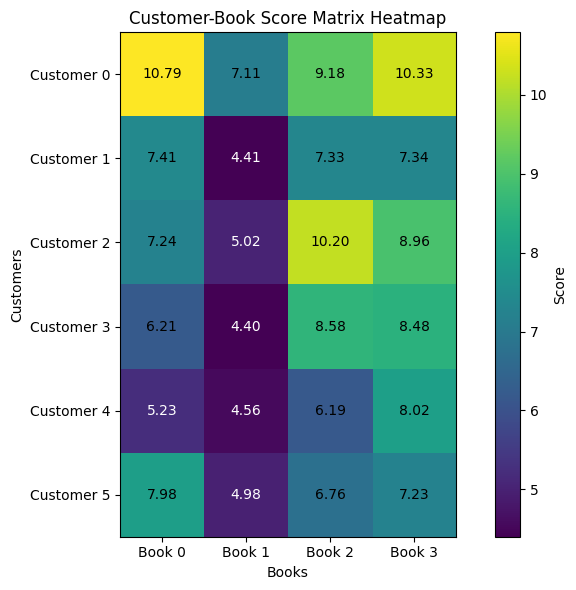

In [6]:
plt.figure(figsize=(8, 6))
plt.imshow(score_matrix, cmap='viridis', interpolation='nearest')
plt.colorbar(label='Score')
plt.title('Customer-Book Score Matrix Heatmap')
plt.xlabel('Books')
plt.ylabel('Customers')
plt.xticks(np.arange(4), [f'Book {i}' for i in range(4)])
plt.yticks(np.arange(6), [f'Customer {i}' for i in range(6)])

# Annotate the values
for i in range(6):
    for j in range(4):
        plt.text(j, i, f'{score_matrix[i, j]:.2f}', ha='center', va='center',
                 color='white' if score_matrix[i, j] < score_matrix.max()/2 else 'black')

plt.tight_layout()
plt.show()